# **Soal UTS**

Nama    : Kevin Davindio Atha

NIM     : 23031554173

Kelas   : Graf Sains Data 2023B 

## **Impor dan konfigurasi**

In [1]:
import os, math, time, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from getpass import getpass
from tqdm import tqdm
from IPython.display import display
from neo4j import GraphDatabase, RoutingControl

##### Penetuan Bobot
Kenapa 1, 3, 5?

Alasannya urutan kekuatan niat. Makin dekat ke pembelian, semakin kuat sinyal bahwa pengunjung menyukai produk itu:

- Melihat (1): bisa karena penasaran, salah klik, atau sekadar menjelajah. Sinyal paling lemah.
- Keranjang (3): pengunjung sudah memutuskan produk itu layak dipertimbangkan. Sinyal sedang.
- Membeli (5): pengunjung benar-benar mengeluarkan uang. Sinyal paling kuat.

In [ ]:
# Konfigurasi koneksi ke Neo4j
URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
DB = "neo4j"
SOURCE = "data"           
BATCH_SIZE = 10_000
SEED = 42                  

# fold training
P1 = ("2015-05-28", "2015-07-28")   
# fold testing
P2 = ("2015-08-06", "2015-08-21")   

# Bobot interaksi untuk VSM
W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
EVENT_TO_REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}

## **2.1 Wrangling dan EDA**

#### **No. 1 dan 2: filter periode dan simpan CSV**

- 2. Kolom timestamp berisi angka panjang seperti 1433221332117 (milidetik sejak 1 Januari 1970), yang tidak bisa dibaca manusia sehingga perlu menambahkan kolom baru datetime yang berisi tanggal biasa seperti 2015-06-02 05:02:12.

In [ ]:
# 1. Mengecek events.csv, jika tidak ada maka mengekstrak dari ecommerce-dataset.zip
zip_path = "ecommerce-dataset.zip"
if not os.path.exists(os.path.join(SOURCE, "events.csv")):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(SOURCE)

# 2. Baca data dan ubah waktu jadi tanggal
events = pd.read_csv(os.path.join(SOURCE, "events.csv"))
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")
print("Rentang data :", events["datetime"].min(), "->", events["datetime"].max())
print("Total baris  :", len(events))

# 3. Menerapkan Filter dan Simpan ke CSV
def filter_period(df, period):
    start = pd.Timestamp(period[0])
    end = pd.Timestamp(period[1]) + pd.Timedelta(days=1)   
    return df[(df["datetime"] >= start) & (df["datetime"] < end)]

COLS = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
df_p1 = filter_period(events, P1).copy()
df_p2 = filter_period(events, P2).copy()
assert len(df_p1) > 0 and len(df_p2) > 0, "Periode di luar rentang data, ganti P1/P2."

P1_CSV = os.path.join(SOURCE, "events_P1.csv")
P2_CSV = os.path.join(SOURCE, "events_P2.csv")
df_p1[COLS].to_csv(P1_CSV, index=False)
df_p2[COLS].to_csv(P2_CSV, index=False)

print(f"P1 {P1}: {len(df_p1):,} baris -> {P1_CSV}")
print(f"P2 {P2}: {len(df_p2):,} baris -> {P2_CSV}")
display(df_p1["event"].value_counts().rename("jumlah P1").to_frame().join(
    df_p2["event"].value_counts().rename("jumlah P2")))

Rentang data : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
Total baris  : 2756101
P1 ('2015-05-28', '2015-07-28'): 1,319,284 baris -> data\events_P1.csv
P2 ('2015-08-06', '2015-08-21'): 285,075 baris -> data\events_P2.csv


,jumlah P1,jumlah P2
event,,
view,1275934,275209
addtocart,32548,7556
transaction,10802,2310


##### **koneksi Database**

In [7]:
PASSWORD = "admin123"
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Terhubung!")

Terhubung!


##### **impor ke Neo4j**

In [ ]:
def create_constraints(session):
    for old in ["visitor_id", "item_id", "category_id"]:
        session.run(f"DROP CONSTRAINT {old} IF EXISTS").consume()
    session.run("CREATE CONSTRAINT visitor_visitorid IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT item_itemid IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()

def reset_database(session, batch=5000):
    """Total reset per batch (hindari kehabisan memori pada data besar)."""
    total = 0
    while True:
        n = session.run(
            "MATCH (n) WITH n LIMIT $b DETACH DELETE n RETURN count(*) AS dihapus",
            b=batch,
        ).single()["dihapus"]
        if n == 0:
            break
        total += n
        print(f"\rSimpul terhapus: {total:,}", end="")
    print("\nDatabase kosong.")


def import_batch(tx, batch):
    for event, rel in EVENT_TO_REL.items():
        rows = [r for r in batch if r["event"] == event]
        if not rows:
            continue
        extra = ", transactionId: row.transactionid" if event == "transaction" else ""
        tx.run(
            f"""
            UNWIND $batch AS row
            MERGE (v:Visitor {{visitorId: row.visitorid}})
            MERGE (i:Item {{itemId: row.itemid}})
            CREATE (v)-[:{rel} {{timestamp: row.timestamp{extra}}}]->(i)
            """,
            batch=rows,
        ).consume()


with driver.session(database=DB) as session:
    reset_database(session)         
    create_constraints(session)

    total_rows = sum(1 for _ in open(P1_CSV, encoding="utf-8")) - 1
    total_chunks = total_rows // BATCH_SIZE + 1
    chunks = pd.read_csv(P1_CSV, chunksize=BATCH_SIZE)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Simpul terhapus: 1,642,645
Database kosong.
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 132/132 [03:39<00:00,  1.66s/it]

Proses impor berhasil.


#### **No. 3: komposisi subgraph**

##### 1. Jenis Simpul
- MATCH (n)	Ambil semua simpul di graf (tanda kurung = simpul, n = nama panggilannya)
- labels(n)[0]	Ambil jenis (label) simpul itu: Visitor atau Item
- count(n)	Hitung ada berapa simpul
- AS jenis_simpul, AS jumlah	Beri nama kolom hasil
- ORDER BY jumlah DESC	Urutkan dari yang terbanyak

##### 2. Jenis Relasi
- MATCH ()-[r]->()	Ambil semua panah (relasi) antara dua simpul apa pun. () kosong berarti “simpul apa saja”
- type(r)	Jenis panahnya: VIEWED, ADDED_TO_CART, atau BOUGHT
- count(r)	Hitung jumlah panah

In [ ]:
def q(query, **params):
    return driver.execute_query(
        query, database_=DB, routing_=RoutingControl.READ,
        result_transformer_=lambda r: r.to_df(), **params,
    )

print("Jenis simpul dan jumlahnya:")
# Melihat Terdapat Simpul Apa saja?
display(q("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC"))

print("Jenis relasi dan jumlahnya:")
# Melihat Terdapat Relasi Apa saja?
display(q("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC"))

Jenis simpul dan jumlahnya:


,jenis_simpul,jumlah
0,Visitor,680693
1,Item,170794


Jenis relasi dan jumlahnya:


,jenis_relasi,jumlah
0,VIEWED,1275934
1,ADDED_TO_CART,32548
2,BOUGHT,10802


#### **No. 4 dan 5: VSM User dan VSM Item**

##### **relasi dari Neo4j**

Membuat Tabel Edges
- Tabel biasa (events / df_p1) seperti tumpukan struk. Setiap aksi satu baris, dicatat apa adanya, termasuk waktunya.
- edges seperti rekap: “A membeli susu 2 kali.” Aksi yang sama digabung, dan waktunya dibuang.

Kenapa perlu edges kalau sudah ada tabel biasa?

- Karena yang dibutuhkan butuhkan untuk matriks VSM hanya: siapa, produk apa, dan seberapa kuat hubungannya. Waktu kejadian tidak diperlukan. Tabel yang lebih ringkas juga lebih cepat diproses.

In [12]:
edges = driver.execute_query(
    """
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel, count(r) AS n
    """,
    database_=DB, routing_=RoutingControl.READ,
    result_transformer_=lambda r: r.to_df(),
)
print("Pasangan (visitor, item, tipe):", len(edges))

Pasangan (visitor, item, tipe): 1060572


##### **Bangun matriks**

In [ ]:
# 1. Memberi bobot pada tiap baris di kolom "w" dengan tipe relasi * jumlah kejadian
edges["w"] = edges["rel"].map(W) * edges["n"]

# 2. Menyatukan per pasangan pengunjung dan produk
A_df = edges.groupby(["u", "i"], as_index=False)["w"].sum()

# u_index[k] = visitorId baris ke-k
u_codes, u_index = pd.factorize(A_df["u"])   

# i_index[k] = itemId kolom ke-k
i_codes, i_index = pd.factorize(A_df["i"])   

# 3 Membuat matriks interaksi Visitor x Item (VSM User)
A = sparse.csr_matrix(
    (A_df["w"].values.astype(float), (u_codes, i_codes)),
    shape=(len(u_index), len(i_index)),
)
B = A.copy()

# 4. Mengubah Angka tidak 0 Menjadi 1 sehingga di matrik hanya ada angka o dan 1
B.data[:] = 1.0         

# 5. Transpose Matriks A  menjadi Item x Visitor (VSM Item)
At = A.T.tocsr()           

user_pos = {int(u): k for k, u in enumerate(u_index)}
item_pos = {int(i): k for k, i in enumerate(i_index)}

# 6. Menampilkan ukuran matriks A dan At
print("A (User x Item):", A.shape, "| At (Item x User):", At.shape)

A (User x Item): (680693, 170794) | At (Item x User): (170794, 680693)


##### **karakteristik VSM (dimensi, shape, distribusi)**

## Apa yang dihitung?

**Shape** adalah ukuran matriks, ditulis (jumlah baris, jumlah kolom). Pada contoh, VSM User berukuran (5, 4) dan VSM Item berukuran (4, 5). Keduanya selalu kebalikan satu sama lain.

**Dimensi vektor** adalah panjang satu vektor, yaitu jumlah kolom. Pada VSM User dimensinya adalah jumlah Item, sedangkan pada VSM Item dimensinya adalah jumlah Visitor. Pada contoh, nilainya 4 dan 5.

**Jumlah vektor** adalah banyaknya baris. Pada VSM User, ini jumlah Visitor. Pada VSM Item, ini jumlah Item. Pada contoh, nilainya 5 dan 4.

**Elemen non-nol** adalah jumlah sel yang berisi interaksi, bukan 0. Nilainya sama untuk kedua matriks karena `At` hanyalah `A` yang diputar. Pada contoh ada 8 sel yang terisi.

**Kepadatan** menunjukkan seberapa penuh matriks. Rumusnya jumlah sel terisi dibagi seluruh sel, lalu dikali 100. Pada contoh, 8 dibagi 20 sel hasilnya 40 persen. Pada data asli nilainya biasanya sangat kecil, misalnya di bawah 1 persen. Matriks seperti itu disebut **sparse** (jarang terisi), dan sebab itulah ia disimpan dalam format sparse yang hanya mencatat sel berisi.

**Derajat** adalah jumlah sel terisi pada satu baris. Pada contoh, derajat V1 sampai V5 berturut-turut 1, 2, 3, 1, 1. Beberapa angka berikut diturunkan dari derajat ini.

**Rata-rata non-nol per vektor** adalah rata-rata derajat. Pada VSM User contoh, (1+2+3+1+1) dibagi 5 hasilnya 1,6. Pada VSM Item, derajat produk P1 sampai P4 adalah 4, 2, 1, 1, sehingga rata-ratanya 2,0.

**Median non-nol per vektor** adalah nilai tengah derajat. Median berguna karena tidak mudah terpengaruh oleh satu simpul yang sangat aktif. Jika median jauh lebih kecil daripada rata-rata, berarti ada segelintir simpul ekstrem yang menarik rata-rata ke atas.

**Maks non-nol per vektor** adalah derajat tertinggi, yaitu vektor yang paling ramai. Pada contoh, nilainya 3 untuk VSM User (pengunjung V3) dan 4 untuk VSM Item (produk P1, yang disentuh 4 pengunjung).

**Persentase vektor dengan 1 non-nol** adalah proporsi vektor yang hanya punya satu interaksi. Vektor seperti ini sulit dibandingkan dengan vektor lain karena informasinya sangat sedikit. Pada contoh, 3 dari 5 pengunjung (60 persen) hanya punya satu interaksi.

**Memori sparse** adalah ukuran penyimpanan matriks. Format sparse menyimpan tiga hal: nilai bobotnya, nomor kolom tiap nilai, dan penunjuk awal tiap baris. Karena hanya sel berisi yang disimpan, hematnya sangat besar untuk matriks yang hampir kosong. Pada data asli angkanya dibaca dalam MB; pada contoh sekecil ini nilainya hampir 0.

## Histogram derajat

Histogram menunjukkan berapa banyak vektor yang punya jumlah interaksi tertentu. Sumbu mendatar adalah derajat, sumbu tegak adalah banyaknya vektor. Kedua sumbu memakai **skala logaritmik** supaya nilai yang sangat kecil dan sangat besar sama-sama terlihat jelas.

Panel kiri memakai VSM User, jadi menunjukkan berapa banyak produk yang disentuh tiap pengunjung. Panel kanan memakai VSM Item, jadi menunjukkan berapa banyak pengunjung yang menyentuh tiap produk.


## hasil pada data asli

Pada data e-commerce, histogram biasanya berbentuk **ekor panjang** (*long tail*). Batang paling tinggi ada di derajat kecil, artinya sebagian besar pengunjung dan produk hanya punya sedikit interaksi. Batang di derajat besar sangat rendah, artinya hanya sedikit pengunjung yang sangat aktif atau produk yang sangat populer.

Beberapa tanda yang perlu diperhatikan:

- Kepadatan sangat kecil berarti matriks sparse, sehingga sebagian besar pasangan pengunjung dan produk tidak pernah berinteraksi.
- Persentase vektor dengan satu non-nol yang tinggi berarti banyak vektor hampir tidak informatif untuk menghitung kemiripan.
- Median yang jauh lebih kecil daripada rata-rata menandakan ekor panjang.
- Nilai maksimum yang sangat besar menunjukkan adanya simpul "super populer".


,VSM User (A)
shape,"(680693, 170794)"
dimensi vektor (= jumlah Item),170794
jumlah vektor (= jumlah Visitor),680693
elemen non-nol,1026940
kepadatan (%),0.00088
rata-rata non-nol per vektor,1.51
median non-nol per vektor,1.0
maks non-nol per vektor,2362
% vektor dengan 1 non-nol,80.26
memori sparse (MB),15.05


,VSM Item (Aᵀ)
shape,"(170794, 680693)"
dimensi vektor (= jumlah Visitor),680693
jumlah vektor (= jumlah Item),170794
elemen non-nol,1026940
kepadatan (%),0.00088
rata-rata non-nol per vektor,6.01
median non-nol per vektor,2.0
maks non-nol per vektor,1621
% vektor dengan 1 non-nol,40.5
memori sparse (MB),13.01


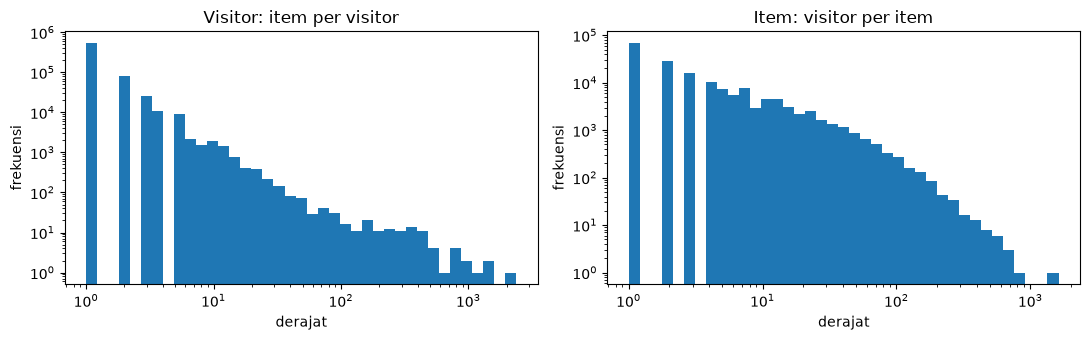

In [14]:
def describe_vsm(M, nama, baris, kolom):
    deg = np.diff(M.indptr)                      # jumlah elemen non-nol per baris
    mem = (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6
    return pd.Series({
        "shape": str(M.shape),
        "dimensi vektor (= jumlah " + kolom + ")": M.shape[1],
        "jumlah vektor (= jumlah " + baris + ")": M.shape[0],
        "elemen non-nol": M.nnz,
        "kepadatan (%)": round(100 * M.nnz / (M.shape[0] * M.shape[1]), 5),
        "rata-rata non-nol per vektor": round(deg.mean(), 2),
        "median non-nol per vektor": float(np.median(deg)),
        "maks non-nol per vektor": int(deg.max()),
        "% vektor dengan 1 non-nol": round(100 * (deg == 1).mean(), 2),
        "memori sparse (MB)": round(mem, 2),
    }, name=nama)


display(describe_vsm(A, "VSM User (A)", "Visitor", "Item").to_frame())
display(describe_vsm(At, "VSM Item (Aᵀ)", "Item", "Visitor").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, M, t in [(ax[0], A, "Visitor: item per visitor"), (ax[1], At, "Item: visitor per item")]:
    a.hist(np.diff(M.indptr), bins=np.logspace(0, np.log10(max(2, np.diff(M.indptr).max())), 40))
    a.set_xscale("log"); a.set_yscale("log"); a.set_title(t); a.set_xlabel("derajat"); a.set_ylabel("frekuensi")
plt.tight_layout(); plt.show()

##### **plot networkx**

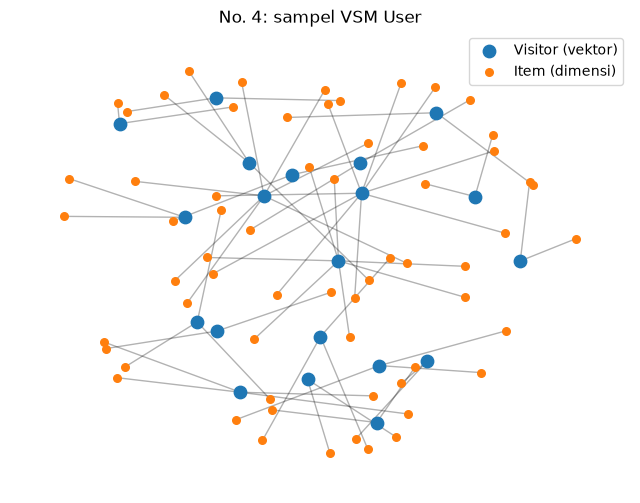

Simpul: 83 | Sisi: 63


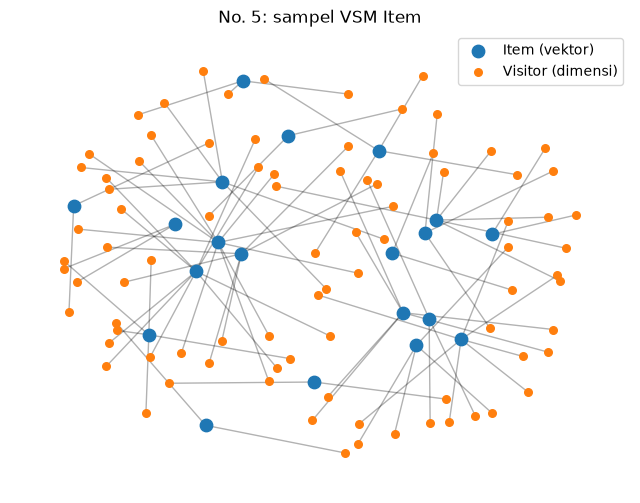

Simpul: 106 | Sisi: 86


In [15]:
def plot_sample(M, nama_baris, nama_kolom, n_rows=20, min_deg=2, max_deg=12, title=""):
    """Gambar graf bipartit dari sampel vektor (baris) beserta elemen non-nolnya."""
    rng_ = np.random.default_rng(SEED)
    deg = np.diff(M.indptr)
    cand = np.where((deg >= min_deg) & (deg <= max_deg))[0]
    pick = rng_.choice(cand, size=min(n_rows, len(cand)), replace=False)
    G = nx.Graph()
    for r in pick:
        for c in M.indices[M.indptr[r]:M.indptr[r + 1]]:
            G.add_edge(("r", int(r)), ("c", int(c)))
    pos = nx.spring_layout(G, seed=SEED, k=0.5)
    rn = [n for n in G if n[0] == "r"]
    cn = [n for n in G if n[0] == "c"]
    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.3)
    nx.draw_networkx_nodes(G, pos, nodelist=rn, node_color="tab:blue", node_size=80, label=nama_baris)
    nx.draw_networkx_nodes(G, pos, nodelist=cn, node_color="tab:orange", node_size=30, label=nama_kolom)
    plt.legend(); plt.title(title); plt.axis("off"); plt.show()
    print(f"Simpul: {G.number_of_nodes()} | Sisi: {G.number_of_edges()}")


plot_sample(A, "Visitor (vektor)", "Item (dimensi)", title="No. 4: sampel VSM User")
plot_sample(At, "Item (vektor)", "Visitor (dimensi)", title="No. 5: sampel VSM Item")

#### **No. 6: perbandingan proyeksi**

Proyeksi Item-Item lebih baik karena:

- Efisien: simpulnya 170.794 (vs 680.693), sisinya sekitar 13,0 juta (vs 23,1 juta), dan memori dense hanya 233 GB (vs 3.707 GB), jadi jauh lebih ringan dihitung dan disimpan.
- Efektif: vektor Item lebih terisi karena satu Item disentuh banyak Visitor, sedangkan banyak Visitor hanya berinteraksi sedikit.

In [ ]:
du = np.diff(B.indptr)                        
di = np.diff(B.T.tocsr().indptr)              

pairs_user = float((di * (di - 1) / 2).sum())  
pairs_item = float((du * (du - 1) / 2).sum())  

perbandingan = pd.DataFrame({
    "Proyeksi User-User": {
        "jumlah simpul": n_u,
        "sisi (batas atas)": pairs_user,
        "sisi / pasangan maks (>1: pasangan berulang)": pairs_user / (n_u * (n_u - 1) / 2),
        "memori matriks dense (GB)": n_u ** 2 * 8 / 1e9,
    },
    "Proyeksi Item-Item": {
        "jumlah simpul": n_i,
        "sisi (batas atas)": pairs_item,
        "sisi / pasangan maks (>1: pasangan berulang)": pairs_item / (n_i * (n_i - 1) / 2),
        "memori matriks dense (GB)": n_i ** 2 * 8 / 1e9,
    },
})
pd.options.display.float_format = "{:,.4f}".format
display(perbandingan)

lebih_baik = "Item-Item" if (n_i < n_u and pairs_item <= pairs_user) else "User-User"
print("Menurut aturan (simpul dan sisi lebih sedikit), proyeksi yang lebih efisien pada data ini:", lebih_baik)
print("Putuskan kesimpulan No. 6 berdasarkan tabel di atas, lalu sesuaikan query No. 7 jika perlu.")

,Proyeksi User-User,Proyeksi Item-Item
jumlah simpul,"680,693.0000","170,794.0000"
sisi (batas atas),"23,126,903.0000","13,048,961.0000"
sisi / pasangan maks (>1: pasangan berulang),0.0001,0.0009
memori matriks dense (GB),"3,706.7437",233.3647


Menurut aturan (simpul dan sisi lebih sedikit), proyeksi yang lebih efisien pada data ini: Item-Item
Putuskan kesimpulan No. 6 berdasarkan tabel di atas, lalu sesuaikan query No. 7 jika perlu.


#### **No. 7: similarity (cosine biner pada proyeksi Item-Item)**

##### **derajat item dan item acuan**

In [ ]:
# Pra-hitung derajat Item (jumlah Visitor unik) sebagai properti simpul
driver.execute_query(
    """
    MATCH (i:Item)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
    WITH i, count(DISTINCT v) AS d
    SET i.degree = d
    """,
    database_=DB,
)

RANK_ACUAN = 20
ref_item = int(i_index[np.argsort(-di)[RANK_ACUAN - 1]])
print("Item acuan:", ref_item, "| jumlah visitor:", int(di[item_pos[ref_item]]))

Item acuan: 112782 | jumlah visitor: 427


##### **(a) 5 Record dengan similarity tertinggi**

In [18]:
CYPHER_TOP5 = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
WITH a, collect(DISTINCT u) AS users
UNWIND users AS u
MATCH (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, b, count(DISTINCT u) AS common, size(users) AS da
WHERE common >= $min_common
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, common AS visitor_sama,
       toFloat(common) / sqrt(da * b.degree) AS cosine
ORDER BY cosine DESC, visitor_sama DESC
LIMIT 5
"""
top5 = driver.execute_query(
    CYPHER_TOP5, ref=ref_item, min_common=2, database_=DB,
    routing_=RoutingControl.READ, result_transformer_=lambda r: r.to_df(),
)
display(top5)

,item_acuan,item_mirip,visitor_sama,cosine
0,112782,441668,55,0.1157
1,112782,103900,21,0.1037
2,112782,422671,22,0.1020
3,112782,372394,4,0.0790
4,112782,408043,3,0.0726


##### **(b) Nilai similarity ke graf**

In [19]:
CYPHER_WRITE = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
WITH a, collect(DISTINCT u) AS users
UNWIND users AS u
MATCH (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, b, count(DISTINCT u) AS common, size(users) AS da
WHERE common >= $min_common
WITH a, b, toFloat(common) / sqrt(da * b.degree) AS cosine
ORDER BY cosine DESC
LIMIT 5
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = cosine, s.metric = 'cosine'
"""
driver.execute_query(CYPHER_WRITE, ref=ref_item, min_common=2, database_=DB)

hasil_b = driver.execute_query(
    """
    MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS score
    ORDER BY score DESC
    """,
    ref=ref_item, database_=DB, routing_=RoutingControl.READ,
    result_transformer_=lambda r: r.to_df(),
)
display(hasil_b)

,item_acuan,item_mirip,score
0,112782,441668,0.1157
1,112782,103900,0.1037
2,112782,422671,0.1020
3,112782,372394,0.0790
4,112782,408043,0.0726


#### **No. 8: graf sebelum dan sesudah similarity**

Sebelum (Neo4j Browser): 
MATCH p = (a:Item {itemId: 112782})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)
          -[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN [441668, 103900, 422671, 372394, 408043]
RETURN p LIMIT 40

Sesudah (Neo4j Browser): 
MATCH p = (a:Item {itemId: 112782})-[:SIMILAR_TO]->(b:Item)
RETURN p



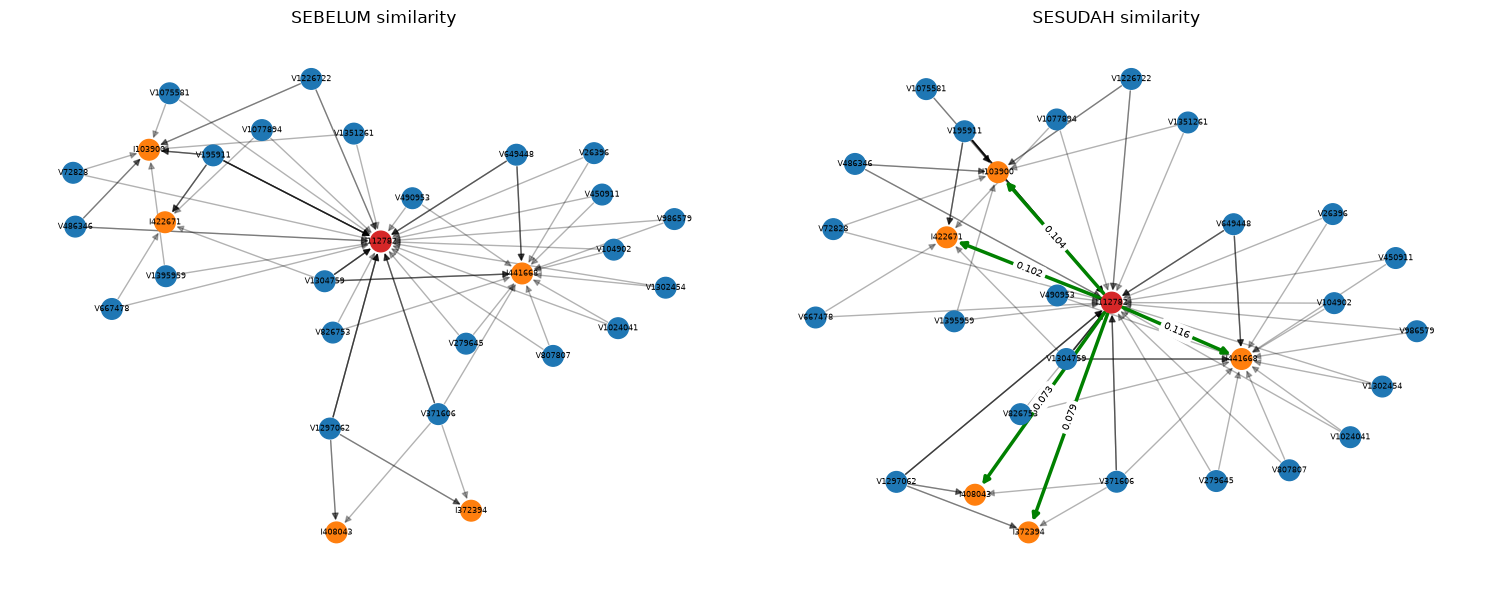

In [20]:
top_ids = [int(x) for x in hasil_b["item_mirip"]]
scores = dict(zip(hasil_b["item_mirip"].astype(int), hasil_b["score"]))

CYPHER_BEFORE = f"""
MATCH p = (a:Item {{itemId: {ref_item}}})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)
          -[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN {top_ids}
RETURN p LIMIT 40
"""
CYPHER_AFTER = f"""
MATCH p = (a:Item {{itemId: {ref_item}}})-[:SIMILAR_TO]->(b:Item)
RETURN p
"""
print("Sebelum (Neo4j Browser):", CYPHER_BEFORE)
print("Sesudah (Neo4j Browser):", CYPHER_AFTER)

rows = driver.execute_query(
    """
    MATCH (a:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
          -[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
    WHERE b.itemId IN $top
    RETURN DISTINCT u.visitorId AS u, type(r1) AS r1, b.itemId AS b, type(r2) AS r2
    LIMIT 40
    """,
    ref=ref_item, top=top_ids, database_=DB, routing_=RoutingControl.READ,
    result_transformer_=lambda r: r.to_df(),
)


def build_graph(with_similarity):
    G = nx.MultiDiGraph()
    for _, r in rows.iterrows():
        G.add_edge(f"V{r['u']}", f"I{ref_item}", label=r["r1"])
        G.add_edge(f"V{r['u']}", f"I{r['b']}", label=r["r2"])
    if with_similarity:
        for b, s in scores.items():
            G.add_edge(f"I{ref_item}", f"I{b}", label=f"SIMILAR_TO {s:.3f}", sim=True)
    return G


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, with_sim, judul in [(axes[0], False, "SEBELUM similarity"), (axes[1], True, "SESUDAH similarity")]:
    G = build_graph(with_sim)
    pos = nx.spring_layout(nx.Graph(G), seed=SEED, k=0.6)
    colors = ["tab:red" if n == f"I{ref_item}" else ("tab:orange" if n.startswith("I") else "tab:blue") for n in G]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=220, ax=ax)
    normal = [(a, b) for a, b, d in G.edges(data=True) if not d.get("sim")]
    simil = [(a, b) for a, b, d in G.edges(data=True) if d.get("sim")]
    nx.draw_networkx_edges(G, pos, edgelist=normal, alpha=0.3, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=simil, edge_color="green", width=2.5, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    if with_sim:
        el = {(a, b): d["label"].replace("SIMILAR_TO ", "") for a, b, d in G.edges(data=True) if d.get("sim")}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=el, font_size=7, ax=ax)
    ax.set_title(judul); ax.axis("off")
plt.tight_layout(); plt.show()

# **2.2 Analytics**

#### **No. 1: user acak dan rekomendasi KNN (k = 5)**

In [21]:
p2 = pd.read_csv(P2_CSV)
p2 = p2[p2["itemid"].isin(item_pos)]                        # hanya item yang dikenal di P1
relevant_by_user = p2.groupby("visitorid")["itemid"].apply(lambda s: set(int(x) for x in s))

norms = np.sqrt(np.asarray(A.multiply(A).sum(axis=1)).ravel())
An = sparse.diags(1.0 / norms) @ A                          # baris dinormalisasi (cosine)
pop_order = np.argsort(-di)                                 # item terpopuler -> terjarang


def recommend(uid, k=5, n_rec=5):
    ui = user_pos[uid]
    sims = (An @ An[ui].T).toarray().ravel()
    sims[ui] = 0.0                                          # buang diri sendiri
    nn = np.argpartition(-sims, k)[:k]
    nn = nn[np.argsort(-sims[nn])]
    nn = nn[sims[nn] > 0]

    scores = A[nn].T @ sims[nn]                             # skor tiap item
    seen = A[ui].indices
    scores[seen] = 0.0
    top = [int(j) for j in np.argsort(-scores)[:n_rec] if scores[j] > 0]
    for j in pop_order:                                     # fallback: item populer
        if len(top) >= n_rec:
            break
        if j not in seen and int(j) not in top:
            top.append(int(j))
    rec_items = [int(i_index[j]) for j in top]
    neighbors = pd.DataFrame({"visitorId": [int(u_index[x]) for x in nn], "cosine": sims[nn]})
    return rec_items, neighbors


rng = np.random.default_rng(SEED)
eligible = sorted(
    int(u) for u in relevant_by_user.index
    if int(u) in user_pos and du[user_pos[int(u)]] >= 2
)
target = int(rng.choice(eligible))
print(f"Kandidat user: {len(eligible):,} | user terpilih (SEED={SEED}): {target}")

rec, neighbors = recommend(target, k=5, n_rec=5)
print("\n5 tetangga terdekat (k = 5):")
display(neighbors)
print("Daftar rekomendasi (top-5):", rec)
print("3 item yang diiklankan   :", rec[:3])

Kandidat user: 4,114 | user terpilih (SEED=42): 130944

5 tetangga terdekat (k = 5):


,visitorId,cosine
0,1153424,0.9562
1,1407216,0.9487
2,1201906,0.9487
3,1393280,0.9487
4,1052462,0.9487


Daftar rekomendasi (top-5): [320494, 138427, 5411, 309778, 370653]
3 item yang diiklankan   : [320494, 138427, 5411]


#### **No. 2: Hit@5 dan NDCG@5**

In [22]:
def hit_at_k(rec_list, relevant, k=5):
    return int(any(i in relevant for i in rec_list[:k]))


def ndcg_at_k(rec_list, relevant, k=5):
    dcg = sum(1.0 / math.log2(r + 2) for r, i in enumerate(rec_list[:k]) if i in relevant)
    idcg = sum(1.0 / math.log2(r + 2) for r in range(min(k, len(relevant))))
    return dcg / idcg if idcg > 0 else 0.0


rel_target = relevant_by_user[target]
print(f"User target {target}")
print("Item relevan di P2     :", sorted(rel_target))
print("Top-5 rekomendasi      :", rec)
print("Hit@5                  :", hit_at_k(rec, rel_target, 5))
print("NDCG@5                 :", round(ndcg_at_k(rec, rel_target, 5), 4))

# Gambaran lebih stabil: rata-rata pada 200 user acak (reproducible)
N_EVAL = min(200, len(eligible))
sample = rng.choice(eligible, size=N_EVAL, replace=False)
hits, ndcgs = [], []
for uid in tqdm(sample, desc="Evaluasi sampel"):
    r_, _ = recommend(int(uid), k=5, n_rec=5)
    rel_ = relevant_by_user[int(uid)]
    hits.append(hit_at_k(r_, rel_, 5))
    ndcgs.append(ndcg_at_k(r_, rel_, 5))
print(f"\nRata-rata pada {N_EVAL} user acak: Hit@5 = {np.mean(hits):.4f} | NDCG@5 = {np.mean(ndcgs):.4f}")

User target 130944
Item relevan di P2     : [460992]
Top-5 rekomendasi      : [320494, 138427, 5411, 309778, 370653]
Hit@5                  : 0
NDCG@5                 : 0.0


Evaluasi sampel: 100%|██████████| 200/200 [00:07<00:00, 27.25it/s]


Rata-rata pada 200 user acak: Hit@5 = 0.0050 | NDCG@5 = 0.0007
